# Practical 4 — Polynomial Regression

**Aim:** Fit curved relationships by expanding the input into polynomial terms (x, x², x³, …) and running ordinary linear
regression on them; choose the degree using train/test error and k-fold cross-validation; report **MSE** and **R²**.

**Datasets:**
* *Main experiment* – a **synthetic** curved dataset generated in the notebook (cubic relationship + random noise). Using a known
  "true" curve lets us check that the method recovers it; the real diabetes data used later is almost perfectly linear, so it would not
  show polynomial behaviour clearly. (To use a UCI dataset instead – e.g. *Auto-MPG*: horsepower → mpg, which is curved – load it with
  `pd.read_csv` and replace `X`, `y` in Step 1.)
* *Second experiment* – Diabetes dataset (UCI/Efron et al., bundled with scikit-learn), `bmi` → disease progression.

**Idea:** ŷ = β₀ + β₁x + β₂x² + … + β_d x^d. The model is *non-linear in x* but still *linear in the coefficients β*,
so OLS still applies. Degree too low → **under-fitting** (high bias); degree too high → **over-fitting** (high variance).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

pd.set_option("display.precision", 4)

## Evaluation helpers (shared by all regression practicals)
* **MSE** = mean((y - ŷ)²) – average squared error (lower is better)
* **R²** = 1 - SS_res / SS_tot – fraction of the variance of *y* explained by the model (1 is perfect, 0 = no better than predicting the mean)
* `kfold_regression` – manual **k-fold cross-validation**; each fold is held out once as the test set.

In [2]:
from sklearn.base import clone
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold


def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return pd.Series({"MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred)})


def kfold_regression(model, X, y, k=5, seed=42, verbose=True):
    """K-fold CV. Returns (per-fold table, mean/std summary)."""
    X, y = np.asarray(X), np.asarray(y)
    kf = KFold(n_splits=k, shuffle=True, random_state=seed)
    rows = []
    for fold, (tr, te) in enumerate(kf.split(X), start=1):
        m = clone(model).fit(X[tr], y[tr])                 # fresh, untrained copy each fold
        r = regression_metrics(y[te], m.predict(X[te]))
        r.name = f"Fold {fold}"
        rows.append(r)
        if verbose:
            print(f"Fold {fold}: train={len(tr)}, test={len(te)}, MSE={r['MSE']:.2f}, R2={r['R2']:.4f}")
    folds = pd.DataFrame(rows)
    return folds, pd.DataFrame({"mean": folds.mean(), "std": folds.std()})

## Step 1 — Create the data and split
True relationship: **y = 2 + 1.5x − 2x² + 0.4x³ + noise** (noise ~ N(0, 3²)), x ∈ [−3, 3], 120 observations.

Train: (90, 1) Test: (30, 1)


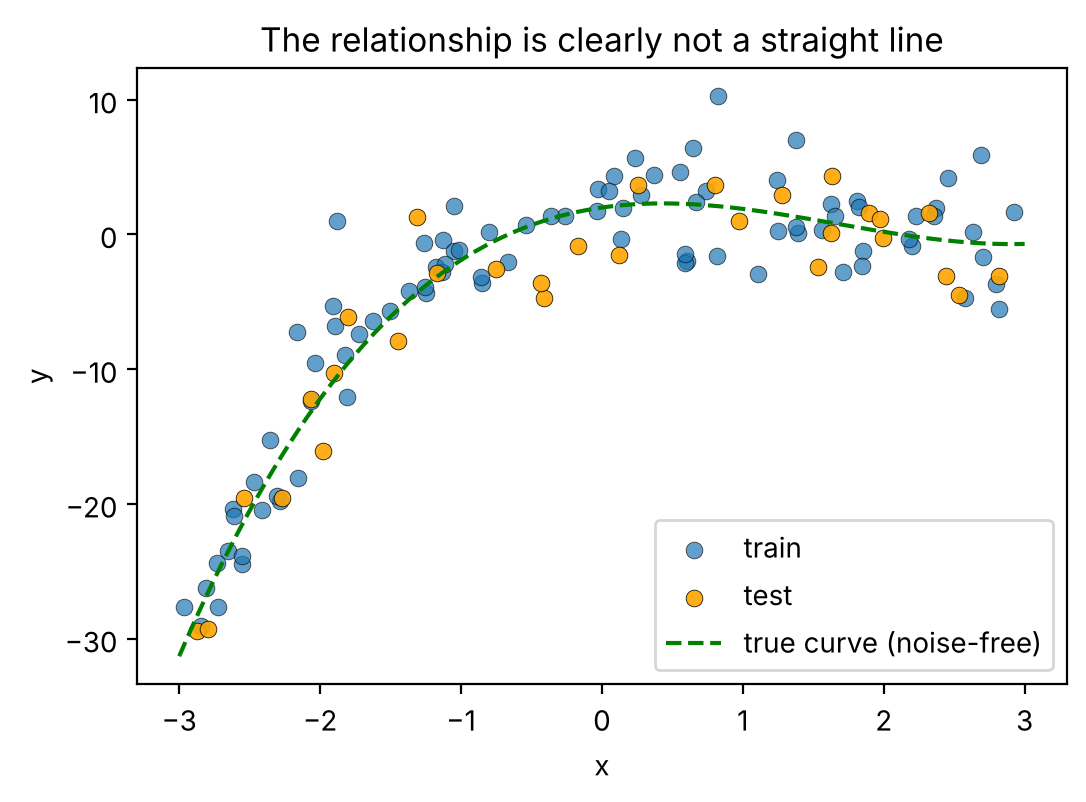

In [3]:
rng = np.random.RandomState(42)
true_coefs = np.array([2.0, 1.5, -2.0, 0.4])                    # β0, β1, β2, β3
x_all = rng.uniform(-3, 3, 120)
y_all = true_coefs[0] + true_coefs[1] * x_all + true_coefs[2] * x_all ** 2 + true_coefs[3] * x_all ** 3 + rng.normal(0, 3, 120)
X = x_all.reshape(-1, 1)                                          # sklearn wants a 2-D feature matrix
y = y_all
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("Train:", X_train.shape, "Test:", X_test.shape)

plt.figure(figsize=(6, 4))
plt.scatter(X_train, y_train, alpha=0.7, edgecolor="k", linewidth=0.3, label="train")
plt.scatter(X_test, y_test, alpha=0.9, c="orange", edgecolor="k", linewidth=0.3, label="test")
g = np.linspace(-3, 3, 200)
plt.plot(g, np.polyval(true_coefs[::-1], g), "g--", label="true curve (noise-free)")
plt.xlabel("x"); plt.ylabel("y"); plt.title("The relationship is clearly not a straight line"); plt.legend(); plt.show()

## Step 2 — What does `PolynomialFeatures` do?
It turns each input value x into the columns **[1, x, x², …, x^d]**. We then hand those columns to
`LinearRegression`, which treats them as ordinary features. Look at the first 3 rows for degree 3:

In [4]:
demo = PolynomialFeatures(degree=3, include_bias=True)
expanded = demo.fit_transform(X_train[:3])
print("Output feature names:", demo.get_feature_names_out(["x"]))
print("\nOriginal x values   :", X_train[:3].ravel().round(4))
print("Expanded matrix:\n", expanded.round(6))
print("\nCheck row 0:  x=%.4f, x²=%.4f, x³=%.4f" % (X_train[0, 0], X_train[0, 0] ** 2, X_train[0, 0] ** 3))

Output feature names: ['1' 'x' 'x^2' 'x^3']

Original x values   : [-0.2636 -0.8492 -1.2471]
Expanded matrix:
 [[ 1.       -0.26358   0.069474 -0.018312]
 [ 1.       -0.849206  0.72115  -0.612405]
 [ 1.       -1.247132  1.555338 -1.939713]]

Check row 0:  x=-0.2636, x²=0.0695, x³=-0.0183


## Step 3 — Manual polynomial fit (degree 3) using the normal equation
1. Build the design matrix A = [1, x, x², x³].
2. Solve (AᵀA)β = Aᵀy.
3. Compare with the scikit-learn pipeline and with the *true* coefficients that generated the data.

In [5]:
x = X_train.ravel()
A = np.column_stack([np.ones_like(x), x, x ** 2, x ** 3])
beta = np.linalg.solve(A.T @ A, A.T @ y_train)
print("Step 3.1  design matrix shape:", A.shape)
print("Step 3.2  β (manual)  [β0, β1, β2, β3] =", beta.round(3))

pipe3 = make_pipeline(PolynomialFeatures(degree=3, include_bias=False), LinearRegression()).fit(X_train, y_train)
lr = pipe3.named_steps["linearregression"]
print("Step 3.3  β (sklearn) [β0, β1, β2, β3] =", np.r_[lr.intercept_, lr.coef_].round(3))
print("Identical:", np.allclose(beta, np.r_[lr.intercept_, lr.coef_]))
print("True coefficients                       =", true_coefs, " (recovered approximately – noise prevents an exact match)")

Step 3.1  design matrix shape: (90, 4)
Step 3.2  β (manual)  [β0, β1, β2, β3] = [ 2.513  0.952 -2.012  0.475]
Step 3.3  β (sklearn) [β0, β1, β2, β3] = [ 2.513  0.952 -2.012  0.475]
Identical: True
True coefficients                       = [ 2.   1.5 -2.   0.4]  (recovered approximately – noise prevents an exact match)


## Step 4 — Sweep the polynomial degree
For degree d = 1…12 we fit a pipeline *StandardScaler → PolynomialFeatures → LinearRegression* (scaling first keeps the
high powers numerically well-behaved), and record the **train MSE**, **test MSE** and **5-fold CV MSE**.
The best degree is where validation error is lowest – *not* where train error is lowest.

,train_MSE,test_MSE,CV_MSE,train_R2,test_R2,CV_R2
degree,,,,,,
1,41.768,38.298,43.491,0.520,0.526,0.475
2,12.181,10.376,13.569,0.860,0.872,0.829
3,8.590,9.047,10.169,0.901,0.888,0.874
4,8.491,8.570,10.515,0.902,0.894,0.871
5,8.486,8.612,10.748,0.903,0.893,0.868
6,8.465,8.388,10.958,0.903,0.896,0.866
7,8.089,8.501,11.072,0.907,0.895,0.866
8,7.984,8.905,11.605,0.908,0.890,0.861
9,7.962,8.638,11.755,0.909,0.893,0.859



Best degree by cross-validation: 3


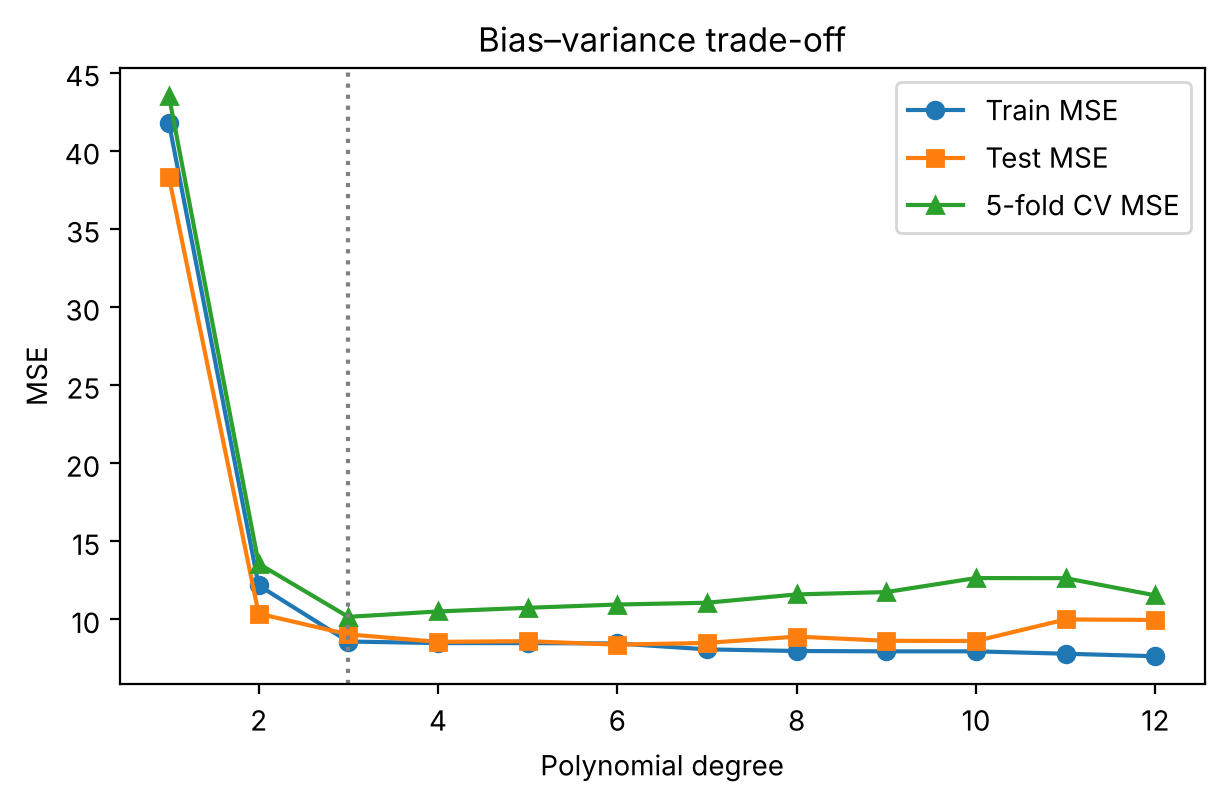

In [6]:
rows = []
for d in range(1, 13):
    model = make_pipeline(StandardScaler(), PolynomialFeatures(d, include_bias=False), LinearRegression())
    model.fit(X_train, y_train)
    tr = regression_metrics(y_train, model.predict(X_train))
    te = regression_metrics(y_test, model.predict(X_test))
    cv = kfold_regression(model, X_train, y_train, k=5, verbose=False)[1]      # CV only on the training part
    rows.append({"degree": d, "train_MSE": tr["MSE"], "test_MSE": te["MSE"], "CV_MSE": cv.loc["MSE", "mean"],
                 "train_R2": tr["R2"], "test_R2": te["R2"], "CV_R2": cv.loc["R2", "mean"]})
sweep = pd.DataFrame(rows).set_index("degree")
display(sweep.round(3))

best_degree = int(sweep["CV_MSE"].idxmin())
print(f"\nBest degree by cross-validation: {best_degree}")

plt.figure(figsize=(7, 4))
plt.plot(sweep.index, sweep["train_MSE"], "o-", label="Train MSE")
plt.plot(sweep.index, sweep["test_MSE"], "s-", label="Test MSE")
plt.plot(sweep.index, sweep["CV_MSE"], "^-", label="5-fold CV MSE")
plt.axvline(best_degree, color="gray", ls=":")
plt.xlabel("Polynomial degree"); plt.ylabel("MSE"); plt.title("Bias–variance trade-off"); plt.legend(); plt.show()

## Step 5 — Visualise under-fit, good fit and over-fit

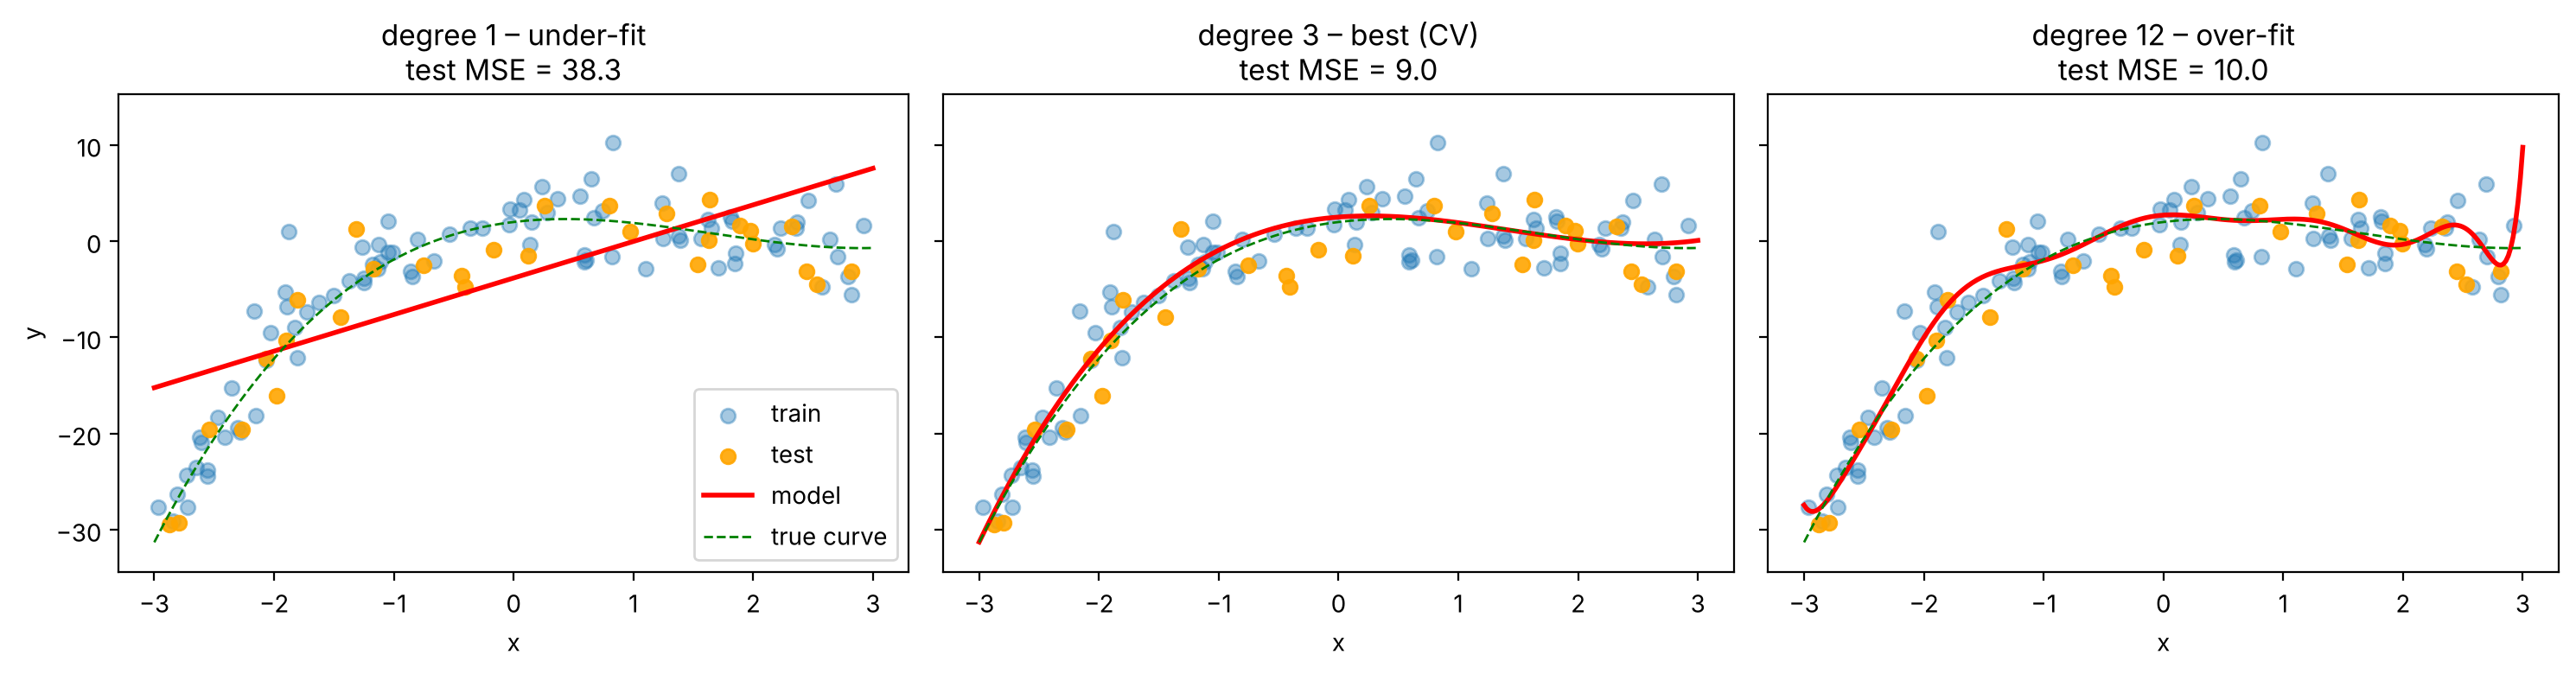

In [7]:
grid = np.linspace(-3, 3, 300).reshape(-1, 1)
degrees = sorted({1, best_degree, 12})
fig, axes = plt.subplots(1, len(degrees), figsize=(5 * len(degrees), 4), sharey=True)
for ax, d in zip(axes, degrees):
    m = make_pipeline(StandardScaler(), PolynomialFeatures(d, include_bias=False), LinearRegression()).fit(X_train, y_train)
    ax.scatter(X_train, y_train, alpha=0.4, label="train")
    ax.scatter(X_test, y_test, alpha=0.9, c="orange", label="test")
    ax.plot(grid, m.predict(grid), "r", lw=2, label="model")
    ax.plot(grid.ravel(), np.polyval(true_coefs[::-1], grid.ravel()), "g--", lw=1, label="true curve")
    ax.set_ylim(y.min() - 5, y.max() + 5)
    label = "under-fit" if d < best_degree else ("over-fit" if d > best_degree else "best (CV)")
    ax.set_title(f"degree {d} – {label}\ntest MSE = {mean_squared_error(y_test, m.predict(X_test)):.1f}")
    ax.set_xlabel("x")
axes[0].set_ylabel("y"); axes[0].legend(); plt.tight_layout(); plt.show()

## Step 6 — Final model: hold-out test + k-fold cross-validation on the whole data

In [8]:
final = make_pipeline(StandardScaler(), PolynomialFeatures(best_degree, include_bias=False), LinearRegression())
final.fit(X_train, y_train)
train_m = regression_metrics(y_train, final.predict(X_train))
test_m = regression_metrics(y_test, final.predict(X_test))

folds, summary = kfold_regression(final, X, y, k=5)
print()
display(folds.round(4))
display(pd.DataFrame({"Train": train_m, "Hold-out test": test_m, "5-fold CV mean": summary["mean"]}).round(4))

Fold 1: train=96, test=24, MSE=9.45, R2=0.8652
Fold 2: train=96, test=24, MSE=9.32, R2=0.9071
Fold 3: train=96, test=24, MSE=12.64, R2=0.8632
Fold 4: train=96, test=24, MSE=6.91, R2=0.9240
Fold 5: train=96, test=24, MSE=8.86, R2=0.8719



,MSE,RMSE,R2
Fold 1,9.4520,3.0744,0.8652
Fold 2,9.3224,3.0533,0.9071
Fold 3,12.6419,3.5556,0.8632
Fold 4,6.9129,2.6292,0.9240
Fold 5,8.8577,2.9762,0.8719


,Train,Hold-out test,5-fold CV mean
MSE,8.5902,9.0471,9.4374
RMSE,2.9309,3.0078,3.0577
R2,0.9013,0.8880,0.8863


## Step 7 — Real data: Diabetes dataset, `bmi` → disease progression
Does a curve help on real data? Same sweep, now on the real BMI feature (5-fold CV on the training part).

In [9]:
dia = load_diabetes(as_frame=True).frame
Xd, yd = dia[["bmi"]].values, dia["target"].values
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.2, random_state=42)
rows = []
for d in range(1, 8):
    m = make_pipeline(StandardScaler(), PolynomialFeatures(d, include_bias=False), LinearRegression()).fit(Xd_tr, yd_tr)
    cv = kfold_regression(m, Xd_tr, yd_tr, k=5, verbose=False)[1]
    rows.append({"degree": d, "train_MSE": mean_squared_error(yd_tr, m.predict(Xd_tr)),
                 "test_MSE": mean_squared_error(yd_te, m.predict(Xd_te)), "CV_MSE": cv.loc["MSE", "mean"], "CV_R2": cv.loc["R2", "mean"]})
real_sweep = pd.DataFrame(rows).set_index("degree")
display(real_sweep.round(3))
print("Best degree by CV on real BMI data:", int(real_sweep["CV_MSE"].idxmin()),
      "→ the real relationship is essentially linear, so extra polynomial terms only fit noise.")

,train_MSE,test_MSE,CV_MSE,CV_R2
degree,,,,
1,3854.113,4061.826,3909.151,0.335
2,3849.333,4085.025,3937.032,0.330
3,3848.447,4064.443,3953.648,0.327
4,3831.057,4226.145,3959.290,0.326
5,3823.764,4085.846,3967.436,0.325
6,3815.307,3979.576,4995.544,0.177
7,3803.861,4193.098,7227.608,-0.143


Best degree by CV on real BMI data: 1 → the real relationship is essentially linear, so extra polynomial terms only fit noise.


### Polynomial features on *all* 10 diabetes features (degree 2)
Degree 2 on 10 inputs creates 10 + 55 = 65 terms (squares and pairwise interactions) for only ~350 training rows – check whether this over-fits.

In [10]:
Xall = dia.drop(columns="target").values
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(Xall, yd, test_size=0.2, random_state=42)
poly_all = make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), LinearRegression()).fit(Xa_tr, ya_tr)
print("Number of generated features:", poly_all.named_steps["polynomialfeatures"].n_output_features_)
display(pd.DataFrame({"Train": regression_metrics(ya_tr, poly_all.predict(Xa_tr)),
                      "Test": regression_metrics(ya_te, poly_all.predict(Xa_te))}).round(4))

Number of generated features: 65


,Train,Test
MSE,2393.1386,3096.0283
RMSE,48.9197,55.6420
R2,0.6062,0.4156


### Conclusion
* `PolynomialFeatures` turns x into [x, x², x³, …]; ordinary least squares on those columns fits a curve. The manual normal-equation solution matches scikit-learn and approximately recovers the true coefficients of the generating cubic.
* A straight line under-fits the curved data (high train *and* test error). Training error keeps falling as the degree rises, but validation error is lowest near the true degree (3) and then rises – over-fitting (see the degree-12 wiggles).
* Choose the degree with validation / cross-validation error, never training error.
* On the real diabetes BMI data the relationship is almost linear, so CV prefers a very low degree; expanding all 10 features to degree 2 over-fits (train error ≪ test error) – regularisation (Ridge/Lasso, Practical 5) is the remedy.